# Phase 1 · D: Efficient Transformer (Sliding-Window Attention + Multi-Query Attention)

## 0. Setup

In [1]:
%pip install -q regex

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, time, math, glob, random, zipfile, shutil, heapq
import multiprocessing as mp
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    import regex as re_u
    HAVE_REGEX = True
except ImportError:
    import re as re_u
    HAVE_REGEX = False
import re as re_std

IS_KAGGLE = os.path.exists("/kaggle/working")
IS_COLAB = "google.colab" in sys.modules

if IS_KAGGLE:
    DEFAULT_WORK = "/kaggle/working/cs781"
elif IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DEFAULT_WORK = "/content/drive/MyDrive/cs781"
else:
    DEFAULT_WORK = str(Path.home() / "cs781")

WORK_DIR = Path(os.environ.get("CAPSTONE_WORK_DIR", DEFAULT_WORK))
ARTIFACTS = WORK_DIR / "artifacts"
DATA_CACHE = ARTIFACTS / "tokenized"
SUBMIT_ROOT = Path(os.environ.get("CAPSTONE_SUBMIT_DIR", WORK_DIR / "submissions")).resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)

HAVE_FORK = "fork" in mp.get_all_start_methods()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
print(f"work dir: {WORK_DIR} | device: {DEVICE} | regex: {HAVE_REGEX} | torch {torch.__version__}")
if DEVICE == "cuda":
    _cap = torch.cuda.get_device_capability()
    print(torch.cuda.get_device_name(0), f"| capability {_cap[0]}.{_cap[1]} ->", "bf16" if _cap[0] >= 8 else "fp16 + GradScaler",
          f"| {torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB")

work dir: /kaggle/working/cs781 | device: cuda | regex: True | torch 2.11.0+cu128
Tesla T4 | capability 7.5 -> fp16 + GradScaler | 16 GB


In [3]:
RUN_NAME = "D_efficient_swa_mqa"
SMOKE_TEST = os.environ.get("CAPSTONE_SMOKE", "0") == "1"

CFG = dict(
    seed=1337,
    data_name="",

    model=dict(
        block_size=2048,
        window=256,
        n_layer=12,
        n_head=10,
        n_kv_head=1,
        d_model=640,
        ffn_mult=8 / 3,
        dropout=0.0,
        rope_theta=10000.0,
        rope_max_len=8192,
        tie_weights=True,
        bias=False,
    ),

    micro_batch=4,
    grad_accum=8,
    token_budget=400_000_000,
    lr=6e-4,
    min_lr=6e-5,
    warmup_steps=500,
    weight_decay=0.1,
    betas=(0.9, 0.95),
    grad_clip=1.0,
    max_steps=None,
    fit_to_time=True,
    max_train_minutes=600,
    eval_interval=500,
    eval_iters=40,
    log_interval=50,
    ckpt_interval=500,
    compile=False,
    resume_from="",

    target_words=128,
    max_new_tokens=320,
    gen_batch_size=32,
    temperature=0.8,
    top_k=50,
    top_p=0.95,
    repetition_penalty=1.1,
    rep_penalty_window=256,
    n_local_eval=300,
)

if SMOKE_TEST:
    CFG.update(max_steps=20, fit_to_time=False, micro_batch=2, grad_accum=1, warmup_steps=5,
               eval_interval=10, eval_iters=2, log_interval=5, ckpt_interval=10,
               max_new_tokens=40, gen_batch_size=4, n_local_eval=4)
    CFG["model"].update(dict(block_size=64, window=16, n_layer=2, n_head=4, n_kv_head=1, d_model=64, rope_max_len=512))
    RUN_NAME += "_smoke"

RUN_DIR = WORK_DIR / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
json.dump(CFG, open(RUN_DIR / "config.json", "w", encoding="utf-8"), indent=2, default=str)
print("run dir:", RUN_DIR, "| smoke test:", SMOKE_TEST)

run dir: /kaggle/working/cs781/runs/D_efficient_swa_mqa | smoke test: False


## 1. Data

In [4]:
def find_tokenized_dir():
    if os.environ.get("CAPSTONE_TOKENIZED_DIR"):
        return Path(os.environ["CAPSTONE_TOKENIZED_DIR"])
    roots = [ARTIFACTS, Path("/kaggle/input"), Path("/content/drive/MyDrive/cs781")]
    hits = []
    for r in roots:
        if r.exists():
            hits += [Path(p).parent for p in glob.glob(f"{r}/**/tokenized/*/meta.json", recursive=True)]
    cands = []
    for h in dict.fromkeys(hits):
        try:
            m = json.load(open(h / "meta.json", encoding="utf-8"))
        except Exception:
            continue
        if bool(m.get("smoke", False)) != SMOKE_TEST:
            continue
        if CFG["data_name"] and h.name != CFG["data_name"]:
            continue
        cands.append((m.get("created", 0), h))
    assert cands, ("no tokenized corpus found. Run Phase1_0_BPE_Tokenizer_and_Data.ipynb first and attach its "
                   "output (Kaggle: Add Input -> Your Work -> that notebook), or set CFG['data_name'].")
    cands.sort(key=lambda c: c[0])
    if len(cands) > 1:
        print("found several tokenized corpora (newest is used, pin one with CFG['data_name']):")
        for c, h in cands:
            print("   ", h)
    return cands[-1][1]

DATA_PATH = find_tokenized_dir()
META = json.load(open(DATA_PATH / "meta.json", encoding="utf-8"))
DATA_NAME = DATA_PATH.name
TEST_FILE = DATA_PATH / META["test_file"] if META.get("test_file") else None

print("corpus folder:", DATA_PATH)
print("mix:", META["spec"]["mix"], "| tokenizer:", META.get("tokenizer_name"))
for p in sorted(DATA_PATH.iterdir()):
    print(f"  {p.name:20s} {p.stat().st_size/1e6:10.1f} MB")

corpus folder: /kaggle/input/notebooks/punnuparashar/bpe-tokenizer/cs781/artifacts/tokenized/data_ad2ea16aef
mix: {'acts': 0.2, 'supreme_court': 0.35, 'high_courts': 0.25, 'tribunals': 0.2} | tokenizer: bpe_v32000_ea9f896448.json
  meta.json                   0.0 MB
  test.json                   3.0 MB
  tokenizer.json              0.4 MB
  train.bin                1000.0 MB
  val.bin                    10.0 MB
  val_prompts.json            1.2 MB


## 2. Tokenizer (byte-level BPE, from scratch)

In [5]:
SPECIAL_TOKENS = ["<|endoftext|>", "<|pad|>", "<|bos|>", "<|sep|>", "<|mask|>"]

def make_pattern(split_digits=True):
    num = r"\p{N}{1,3}" if split_digits else r"\p{N}+"
    return (r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?""" + num +
            r"""| ?[^\s\p{L}\p{N}]+[\r\n]*|\s*[\r\n]+|\s+(?!\S)|\s+""")

def _merge_ids(ids, pair, new_id):
    out, i, n = [], 0, len(ids)
    a, b = pair
    while i < n:
        if i < n - 1 and ids[i] == a and ids[i + 1] == b:
            out.append(new_id); i += 2
        else:
            out.append(ids[i]); i += 1
    return out

_COUNT_PAT = None
def _count_words(texts_and_pattern):
    texts, pattern = texts_and_pattern
    global _COUNT_PAT
    if _COUNT_PAT is None or _COUNT_PAT.pattern != pattern:
        _COUNT_PAT = re_u.compile(pattern)
    c = Counter()
    for t in texts:
        c.update(_COUNT_PAT.findall(t))
    return c

In [6]:
class BPETokenizer:
    def __init__(self, merges=None, pattern=None, specials=SPECIAL_TOKENS):
        self.pattern = pattern or make_pattern()
        self.pat = re_u.compile(self.pattern)
        self.merges = [tuple(m) for m in (merges or [])]
        self.specials = list(specials)
        self._build()

    def _build(self):
        self.ranks = {p: i for i, p in enumerate(self.merges)}
        self.vocab = {i: bytes([i]) for i in range(256)}
        for i, (a, b) in enumerate(self.merges):
            self.vocab[256 + i] = self.vocab[a] + self.vocab[b]
        base = 256 + len(self.merges)
        self.n_regular = base
        self.special_to_id = {s: base + i for i, s in enumerate(self.specials)}
        self.id_to_special = {v: k for k, v in self.special_to_id.items()}
        self.vocab_size = base + len(self.specials)
        self._special_re = re_u.compile("(" + "|".join(re_u.escape(s) for s in self.specials) + ")")
        self.cache = {}

    def __len__(self):
        return self.vocab_size

    @property
    def eot_id(self): return self.special_to_id["<|endoftext|>"]
    @property
    def pad_id(self): return self.special_to_id["<|pad|>"]
    @property
    def bos_id(self): return self.special_to_id["<|bos|>"]
    @property
    def sep_id(self): return self.special_to_id["<|sep|>"]
    @property
    def mask_id(self): return self.special_to_id["<|mask|>"]

    @classmethod
    def train(cls, text_iter, vocab_size, pattern, min_word_freq=2, n_proc=1, verbose=True):
        t0 = time.time()
        def batches(it, size=200):
            buf = []
            for t in it:
                buf.append(t)
                if len(buf) == size:
                    yield (buf, pattern); buf = []
            if buf:
                yield (buf, pattern)
        counts = Counter()
        if n_proc > 1 and HAVE_FORK:
            with mp.get_context("fork").Pool(n_proc) as pool:
                for c in pool.imap_unordered(_count_words, batches(text_iter), chunksize=1):
                    counts.update(c)
        else:
            for b in batches(text_iter):
                counts.update(_count_words(b))
        words, freqs = [], []
        for w, c in counts.items():
            if c >= min_word_freq:
                words.append(list(w.encode("utf-8"))); freqs.append(c)
        del counts
        if verbose:
            print(f"[bpe] {len(words):,} word types after min_freq={min_word_freq} ({time.time()-t0:.0f}s)")

        pair_counts = defaultdict(int)
        where = defaultdict(list)
        for i, w in enumerate(words):
            f = freqs[i]
            seen = set()
            for p in zip(w, w[1:]):
                pair_counts[p] += f
                if p not in seen:
                    where[p].append(i); seen.add(p)
        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)

        n_merges = vocab_size - 256 - len(SPECIAL_TOKENS)
        assert n_merges > 0, "vocab_size too small"
        merges = []
        while len(merges) < n_merges and heap:
            negc, p = heapq.heappop(heap)
            cur = pair_counts.get(p, 0)
            if cur <= 0 or -negc != cur:
                continue
            new_id = 256 + len(merges)
            merges.append(p)
            touched = set()
            for i in set(where.pop(p, ())):
                w = words[i]
                nw = _merge_ids(w, p, new_id)
                if len(nw) == len(w):
                    continue
                f = freqs[i]
                old_pc = Counter(zip(w, w[1:]))
                new_pc = Counter(zip(nw, nw[1:]))
                for q, n in old_pc.items():
                    pair_counts[q] -= n * f; touched.add(q)
                for q, n in new_pc.items():
                    pair_counts[q] += n * f; touched.add(q)
                    if q not in old_pc:
                        where[q].append(i)
                words[i] = nw
            for q in touched:
                c = pair_counts.get(q, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, q))
                else:
                    pair_counts.pop(q, None)
            if verbose and len(merges) % 2000 == 0:
                print(f"[bpe] {len(merges):,}/{n_merges:,} merges ({time.time()-t0:.0f}s)")
        if verbose:
            print(f"[bpe] done: {len(merges):,} merges in {time.time()-t0:.0f}s")
        if len(merges) < n_merges:
            print(f"[bpe] warning: only {len(merges):,}/{n_merges:,} merges possible -> vocab is smaller than requested "
                  "(raise tok_train_chars or lower tok_min_word_freq)")
        return cls(merges=merges, pattern=pattern)

    def _encode_word(self, s):
        hit = self.cache.get(s)
        if hit is not None:
            return hit
        ids = list(s.encode("utf-8"))
        ranks = self.ranks
        while len(ids) >= 2:
            best, best_r = None, None
            for p in zip(ids, ids[1:]):
                r = ranks.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best, best_r = p, r
            if best is None:
                break
            ids = _merge_ids(ids, best, 256 + best_r)
        if len(self.cache) > 500_000:
            self.cache.clear()
        self.cache[s] = ids
        return ids

    def encode_ordinary(self, text):
        out = []
        for w in self.pat.findall(text):
            out.extend(self._encode_word(w))
        return out

    def encode(self, text, allow_special=True):
        if not allow_special:
            return self.encode_ordinary(text)
        out = []
        for part in self._special_re.split(text):
            if part in self.special_to_id:
                out.append(self.special_to_id[part])
            elif part:
                out.extend(self.encode_ordinary(part))
        return out

    def decode(self, ids, skip_special=True):
        buf, out = [], []
        for i in ids:
            i = int(i)
            if i in self.id_to_special:
                if buf:
                    out.append(b"".join(buf).decode("utf-8", errors="replace")); buf = []
                if not skip_special:
                    out.append(self.id_to_special[i])
            else:
                buf.append(self.vocab[i])
        if buf:
            out.append(b"".join(buf).decode("utf-8", errors="replace"))
        return "".join(out)

    def save(self, path, meta=None):
        path = Path(path)
        tmp = path.with_suffix(".tmp")
        json.dump({"type": "byte_bpe", "pattern": self.pattern, "specials": self.specials,
                   "merges": self.merges, "vocab_size": self.vocab_size, "meta": meta or {}},
                  open(tmp, "w", encoding="utf-8"))
        os.replace(tmp, path)

    @classmethod
    def load(cls, path):
        d = json.load(open(path, encoding="utf-8"))
        return cls(merges=d["merges"], pattern=d["pattern"], specials=d["specials"])

In [7]:
assert HAVE_REGEX, "the tokenizer pattern needs the `regex` package: run `%pip install regex` and restart"
TOK_FILE = DATA_PATH / META["tokenizer_file"]
tok = BPETokenizer.load(TOK_FILE)
VOCAB_SIZE = tok.vocab_size
assert VOCAB_SIZE == META["vocab_size"], "tokenizer / corpus mismatch"
print(f"loaded {META.get('tokenizer_name', TOK_FILE.name)} from {TOK_FILE}")
print(f"vocab size: {VOCAB_SIZE} ({len(tok.merges):,} merges + 256 bytes + {len(tok.specials)} specials)")
print("eot/pad/bos/sep/mask:", tok.eot_id, tok.pad_id, tok.bos_id, tok.sep_id, tok.mask_id)

_s = "The appellant filed a writ petition under Article 226 of the Constitution."
assert tok.decode(tok.encode(_s)) == _s, "tokenizer round-trip failed"
print("example:", [tok.decode([i]) for i in tok.encode(_s)])

loaded bpe_v32000_ea9f896448.json from /kaggle/input/notebooks/punnuparashar/bpe-tokenizer/cs781/artifacts/tokenized/data_ad2ea16aef/tokenizer.json
vocab size: 32000 (31,739 merges + 256 bytes + 5 specials)
eot/pad/bos/sep/mask: 31995 31996 31997 31998 31999
example: ['The', ' appellant', ' filed', ' a', ' writ', ' petition', ' under', ' Article', ' 226', ' of', ' the', ' Constitution', '.']


## 3. Tokenized corpus

In [8]:
NP_DTYPE = np.dtype(META["dtype"])

def load_split(split):
    return np.memmap(DATA_PATH / f"{split}.bin", dtype=NP_DTYPE, mode="r")

for split in ("train", "val"):
    assert len(load_split(split)) == META["total"][split], f"{split}.bin is incomplete"
VAL_PROMPTS = json.load(open(DATA_PATH / "val_prompts.json", encoding="utf-8"))

print(f"tokens: train={len(load_split('train')):,} | val={len(load_split('val')):,}")
print("per source:", json.dumps(META["per_source"]))
print(f"held-out prompts: {len(VAL_PROMPTS)} | test file: {TEST_FILE}")
print("decoded train sample:", repr(tok.decode(load_split("train")[1000:1050].tolist())))

tokens: train=500,022,499 | val=5,022,617
per source: {"acts": {"train": 100019678, "val": 1019925}, "supreme_court": {"train": 175001865, "val": 1750621}, "high_courts": {"train": 125000568, "val": 1250004}, "tribunals": {"train": 100000388, "val": 1002067}}
held-out prompts: 300 | test file: /kaggle/input/notebooks/punnuparashar/bpe-tokenizer/cs781/artifacts/tokenized/data_ad2ea16aef/test.json
decoded train sample: ' to the Government for regularisation subject to payment of such amount as may be determined by it having regard to,-\n(i) the situation of the building;\n(ii) the nature and extent of deviation;\n(iii) any other relevant factors:\nProvided that'


## 4. Batching

In [9]:
def to_dev(batch):
    out = {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}
    return out

def _pin(batch):
    return {k: v.pin_memory() for k, v in batch.items()} if DEVICE == "cuda" else batch

BLOCK = CFG["model"]["block_size"]
assert BLOCK % CFG["model"]["window"] == 0, "block_size must be a multiple of window"
TOKENS_PER_SAMPLE = BLOCK

def get_batch(split, B=None, rng=None, eval_mode=False):
    B = B or CFG["micro_batch"]
    rng = rng or np.random
    data = load_split(split)
    ix = rng.randint(0, len(data) - BLOCK - 1, size=B)
    seq = torch.from_numpy(np.stack([data[i:i + BLOCK + 1].astype(np.int64) for i in ix]))
    return _pin({"idx": seq[:, :-1].contiguous(), "targets": seq[:, 1:].contiguous()})

def compute_loss(model, batch):
    _, loss = model(batch["idx"], targets=batch["targets"])
    return loss

_b = get_batch("train", 2)
print({k: tuple(v.shape) for k, v in _b.items()})

{'idx': (2, 2048), 'targets': (2, 2048)}


## 5. Model

In [10]:
def _ffn_hidden(d_model, mult, multiple_of=64):
    h = int(mult * d_model)
    return multiple_of * ((h + multiple_of - 1) // multiple_of)

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)

class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, max_len, theta=10000.0):
        super().__init__()
        assert head_dim % 2 == 0, "RoPE needs an even head_dim"
        inv_freq = 1.0 / theta ** (torch.arange(0, head_dim, 2).float() / head_dim)
        freqs = torch.outer(torch.arange(max_len).float(), inv_freq)
        self.register_buffer("cos", freqs.cos(), persistent=False)
        self.register_buffer("sin", freqs.sin(), persistent=False)

    def forward(self, x, pos0=0):
        T = x.size(-2)
        assert pos0 + T <= self.cos.size(0), f"position {pos0 + T} > RoPE table {self.cos.size(0)}"
        cos, sin = self.cos[pos0:pos0 + T], self.sin[pos0:pos0 + T]
        x1, x2 = x.float().chunk(2, dim=-1)
        return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)

class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden, dropout=0.0, bias=False):
        super().__init__()
        self.w12 = nn.Linear(d_model, 2 * hidden, bias=bias)
        self.proj = nn.Linear(hidden, d_model, bias=bias)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        a, b = self.w12(x).chunk(2, dim=-1)
        return self.drop(self.proj(F.silu(a) * b))

def init_weights_(model, n_layer):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
    for name, p in model.named_parameters():
        if name.endswith("proj.weight"):
            nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

def lm_loss(logits, targets):
    return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)

In [11]:
class LocalMQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd, self.window = n_head, n_kv_head, d_model // n_head, window
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)
        self._mask_cache = {}

    def _block_mask(self, nb, device):
        key = (nb, str(device))
        m = self._mask_cache.get(key)
        if m is None:
            W = self.window
            a = torch.arange(W, device=device)[:, None]
            b = torch.arange(2 * W, device=device)[None, :]
            keep = ((b > a) & (b <= a + W))[None].repeat(nb, 1, 1)
            keep[0, :, :W] = False
            m = keep[None, None].expand(1, self.n_head, nb, W, 2 * W).reshape(1, self.n_head * nb, W, 2 * W)
            self._mask_cache = {key: m}
        return m

    def _blocked(self, q, k, v):
        B, H, T, hd = q.shape
        W, Hkv = self.window, k.size(1)
        Tp = -(-T // W) * W
        if Tp != T:
            q, k, v = (F.pad(t, (0, 0, 0, Tp - T)) for t in (q, k, v))
        nb = Tp // W
        k = F.pad(k, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        v = F.pad(v, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        rep = H // Hkv
        k = k[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        v = v[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        qb = q.reshape(B, H * nb, W, hd)
        y = F.scaled_dot_product_attention(qb, k, v, attn_mask=self._block_mask(nb, q.device),
                                           dropout_p=self.dropout if self.training else 0.0)
        return y.reshape(B, H, Tp, hd)[:, :, :T]

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None and "k" in cache:
            assert T == 1, "cached decoding feeds one token at a time"
            k = torch.cat([cache["k"], k], 2)[:, :, -self.window:]
            v = torch.cat([cache["v"], v], 2)[:, :, -self.window:]
            cache["k"], cache["v"] = k, v
            rep = self.n_head // self.n_kv
            y = F.scaled_dot_product_attention(q, k.repeat_interleave(rep, 1), v.repeat_interleave(rep, 1))
        else:
            y = self._blocked(q, k, v)
            if cache is not None:
                cache["k"], cache["v"] = k[:, :, -self.window:], v[:, :, -self.window:]
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

In [12]:
class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = LocalMQAttention(d_model, n_head, n_kv_head, window, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class EfficientLM(nn.Module):
    def __init__(self, vocab_size, block_size, window=256, pad_id=None, n_layer=12, n_head=10, n_kv_head=1,
                 d_model=640, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, rope_max_len=8192,
                 tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EfficientLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.window, self.pad_id, self.n_layer = block_size, window, pad_id, n_layer
        self.max_pos = max(rope_max_len, block_size)
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, self.max_pos, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, window, hidden, dropout, bias)
                                     for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EfficientLM

In [13]:
torch.manual_seed(CFG["seed"])
MODEL_KW = dict(CFG["model"], vocab_size=VOCAB_SIZE, pad_id=tok.pad_id)
model = MODEL_CLASS(**MODEL_KW).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
n_emb = model.tok_emb.weight.numel()
print(f"{MODEL_CLASS.__name__}: {n_params/1e6:.2f}M parameters ({(n_params-n_emb)/1e6:.2f}M non-embedding)")
if not SMOKE_TEST:
    assert 50e6 <= n_params <= 300e6, f"Phase-1 rule: 50M-300M parameters (got {n_params/1e6:.1f}M)"

_b = to_dev(get_batch("train"))
_loss = compute_loss(model, _b)
_loss.backward(); model.zero_grad(set_to_none=True)
print("initial loss:", round(_loss.item(), 3), "| ln(V) =", round(math.log(VOCAB_SIZE), 3))

EfficientLM: 71.12M parameters (50.64M non-embedding)
initial loss: 10.519 | ln(V) = 10.373


## 6. Training

In [14]:
use_bf16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8
AMP_DTYPE = torch.bfloat16 if use_bf16 else torch.float16
amp_ctx = (lambda: torch.autocast("cuda", dtype=AMP_DTYPE)) if DEVICE == "cuda" else (lambda: torch.autocast("cpu", enabled=False))
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and not use_bf16))

decay, no_decay = [], []
for n, p in model.named_parameters():
    if p.requires_grad:
        (decay if p.dim() >= 2 else no_decay).append(p)
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": CFG["weight_decay"]},
                               {"params": no_decay, "weight_decay": 0.0}],
                              lr=CFG["lr"], betas=CFG["betas"], fused=use_bf16)

TOKENS_PER_STEP = CFG["micro_batch"] * CFG["grad_accum"] * TOKENS_PER_SAMPLE
BUDGET_STEPS = CFG["max_steps"] or max(1, CFG["token_budget"] // TOKENS_PER_STEP)
print(f"tokens/step={TOKENS_PER_STEP:,} | budget steps={BUDGET_STEPS:,} "
      f"(~{BUDGET_STEPS * TOKENS_PER_STEP / 1e6:.0f}M tokens, corpus has {len(load_split('train'))/1e6:.0f}M)")

def lr_at(step, max_steps):
    if step < CFG["warmup_steps"]:
        return CFG["lr"] * (step + 1) / CFG["warmup_steps"]
    prog = min(1.0, (step - CFG["warmup_steps"]) / max(1, max_steps - CFG["warmup_steps"]))
    return CFG["min_lr"] + 0.5 * (CFG["lr"] - CFG["min_lr"]) * (1 + math.cos(math.pi * prog))

tokens/step=65,536 | budget steps=6,103 (~400M tokens, corpus has 500M)


In [15]:
@torch.no_grad()
def estimate_loss(iters=None):
    model.eval()
    out = {}
    for k, split in enumerate(("train", "val")):
        rng = np.random.RandomState(CFG["seed"] + 1000 + k)
        losses = []
        for _ in range(iters or CFG["eval_iters"]):
            with amp_ctx():
                losses.append(compute_loss(model, to_dev(get_batch(split, rng=rng, eval_mode=True))).item())
        out[split] = float(np.mean(losses))
    model.train()
    return out

def save_ckpt(path, state, with_optimizer=True):
    tmp = str(path) + ".tmp"
    blob = {"model": model.state_dict(), "state": state, "cfg": CFG, "model_kw": MODEL_KW,
            "model_class": type(model).__name__, "data": DATA_NAME, "tokenizer_file": META["tokenizer_file"]}
    if with_optimizer:
        blob.update(optimizer=optimizer.state_dict(), scaler=scaler.state_dict(),
                    rng={"torch": torch.get_rng_state(), "numpy": np.random.get_state(), "py": random.getstate(),
                         "cuda": torch.cuda.get_rng_state_all() if DEVICE == "cuda" else None})
    torch.save(blob, tmp)
    os.replace(tmp, path)

def find_resume():
    if CFG["resume_from"]:
        return Path(CFG["resume_from"])
    if (RUN_DIR / "ckpt_last.pt").exists():
        return RUN_DIR / "ckpt_last.pt"
    hits = glob.glob(f"/kaggle/input/**/runs/{RUN_NAME}/ckpt_last.pt", recursive=True)
    return Path(hits[0]) if hits else None

state = {"step": 0, "best_val": float("inf"), "tokens": 0, "history": [], "max_steps": None}
rp = find_resume()
if rp:
    ck = torch.load(rp, map_location="cpu", weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scaler.load_state_dict(ck["scaler"]); state = ck["state"]
    torch.set_rng_state(ck["rng"]["torch"].cpu()); np.random.set_state(ck["rng"]["numpy"]); random.setstate(ck["rng"]["py"])
    if DEVICE == "cuda" and ck["rng"]["cuda"] is not None:
        torch.cuda.set_rng_state_all([s.cpu() for s in ck["rng"]["cuda"]])
    if rp.parent != RUN_DIR:
        if (rp.parent / "ckpt_best.pt").exists() and not (RUN_DIR / "ckpt_best.pt").exists():
            shutil.copy(rp.parent / "ckpt_best.pt", RUN_DIR / "ckpt_best.pt")
    del ck
    print(f"resumed from {rp} at step {state['step']} (max_steps {state.get('max_steps')})")
MAX_STEPS = state.get("max_steps") or BUDGET_STEPS
state["max_steps"] = MAX_STEPS

In [16]:
CALIB = (10, 60)
calibrate = CFG["fit_to_time"] and state["step"] < CALIB[0] and MAX_STEPS > CALIB[1] + 10

train_model = torch.compile(model) if CFG["compile"] else model
t_start = time.time(); t_last = t_start; t_calib = None
model.train()
while state["step"] < MAX_STEPS:
    step = state["step"]
    lr = lr_at(step, MAX_STEPS)
    for g in optimizer.param_groups:
        g["lr"] = lr
    loss_acc = 0.0
    for _ in range(CFG["grad_accum"]):
        with amp_ctx():
            loss = compute_loss(train_model, to_dev(get_batch("train"))) / CFG["grad_accum"]
        scaler.scale(loss).backward()
        loss_acc += loss.item()
    scaler.unscale_(optimizer)
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
    scaler.step(optimizer); scaler.update()
    optimizer.zero_grad(set_to_none=True)
    state["step"] += 1; state["tokens"] += TOKENS_PER_STEP
    step = state["step"]

    if calibrate and step == CALIB[0]:
        t_calib = time.time()
    if calibrate and step == CALIB[1] and t_calib is not None:
        sec_per_step = (time.time() - t_calib) / (CALIB[1] - CALIB[0])
        left = CFG["max_train_minutes"] * 60 - (time.time() - t_start)
        fit = step + int(0.93 * left / sec_per_step)
        if fit < MAX_STEPS:
            print(f"[fit_to_time] {sec_per_step:.2f}s/step -> only {fit:,} of {MAX_STEPS:,} steps fit in "
                  f"{CFG['max_train_minutes']} min; schedule shortened to {fit:,} steps (~{fit*TOKENS_PER_STEP/1e6:.0f}M tokens)")
            MAX_STEPS = max(fit, CFG["warmup_steps"] + 1)
            state["max_steps"] = MAX_STEPS
        else:
            print(f"[fit_to_time] {sec_per_step:.2f}s/step -> all {MAX_STEPS:,} steps fit "
                  f"(~{(MAX_STEPS - step) * sec_per_step / 60:.0f} min left)")

    if step % CFG["log_interval"] == 0:
        dt = time.time() - t_last; t_last = time.time()
        tps = TOKENS_PER_STEP * CFG["log_interval"] / max(dt, 1e-9)
        print(f"step {step:6d}/{MAX_STEPS} | loss {loss_acc:.4f} | lr {lr:.2e} | gnorm {float(gnorm):.2f} | "
              f"{tps:,.0f} tok/s | {(time.time()-t_start)/60:.1f} min")
    if step % CFG["eval_interval"] == 0 or step == MAX_STEPS:
        ev = estimate_loss()
        state["history"].append({"step": step, "tokens": state["tokens"], **ev,
                                 "val_ppl": math.exp(min(ev["val"], 20)), "time_min": (time.time() - t_start) / 60})
        print(f"  eval @ {step}: train {ev['train']:.4f} | val {ev['val']:.4f} | val ppl {math.exp(min(ev['val'], 20)):.2f}")
        if ev["val"] < state["best_val"]:
            state["best_val"] = ev["val"]
            save_ckpt(RUN_DIR / "ckpt_best.pt", state, with_optimizer=False)
            print("  new best -> ckpt_best.pt")
        json.dump(state["history"], open(RUN_DIR / "history.json", "w", encoding="utf-8"), indent=1)
    if step % CFG["ckpt_interval"] == 0:
        save_ckpt(RUN_DIR / "ckpt_last.pt", state)
    if (time.time() - t_start) / 60 > CFG["max_train_minutes"]:
        print("time budget reached -> checkpointing and stopping")
        break
save_ckpt(RUN_DIR / "ckpt_last.pt", state)
json.dump(state["history"], open(RUN_DIR / "history.json", "w", encoding="utf-8"), indent=1)
print("training finished at step", state["step"], "| best val", state["best_val"])

step     50/6103 | loss 7.6693 | lr 6.00e-05 | gnorm 3.28 | 18,705 tok/s | 2.9 min
[fit_to_time] 3.57s/step -> all 6,103 steps fit (~360 min left)
step    100/6103 | loss 5.8363 | lr 1.20e-04 | gnorm 1.68 | 17,692 tok/s | 6.0 min
step    150/6103 | loss 5.1360 | lr 1.80e-04 | gnorm 1.42 | 17,740 tok/s | 9.1 min
step    200/6103 | loss 4.5834 | lr 2.40e-04 | gnorm 2.00 | 17,539 tok/s | 12.2 min
step    250/6103 | loss 4.1343 | lr 3.00e-04 | gnorm 1.99 | 17,804 tok/s | 15.3 min
step    300/6103 | loss 3.9635 | lr 3.60e-04 | gnorm 1.25 | 17,923 tok/s | 18.3 min
step    350/6103 | loss 3.8105 | lr 4.20e-04 | gnorm 1.35 | 17,910 tok/s | 21.4 min
step    400/6103 | loss 3.7873 | lr 4.80e-04 | gnorm 1.15 | 17,871 tok/s | 24.4 min
step    450/6103 | loss 3.5453 | lr 5.40e-04 | gnorm 1.02 | 17,830 tok/s | 27.5 min
step    500/6103 | loss 3.6863 | lr 6.00e-04 | gnorm 0.87 | 17,986 tok/s | 30.5 min
  eval @ 500: train 3.5313 | val 3.3122 | val ppl 27.45
  new best -> ckpt_best.pt
step    550/6103

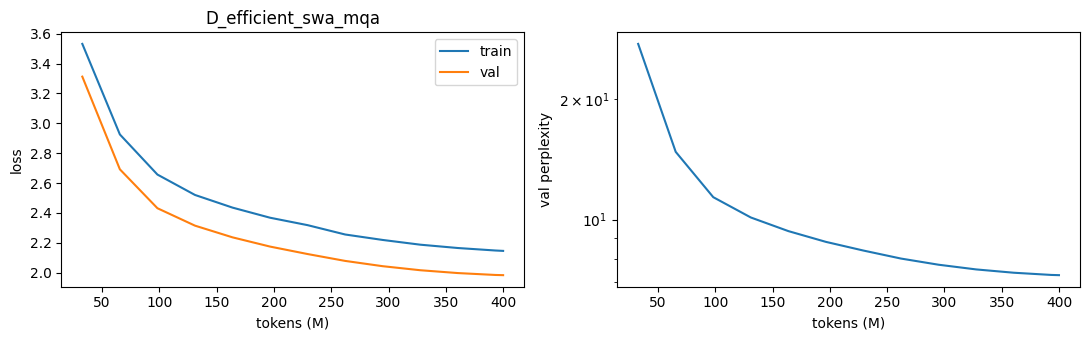

In [17]:
import matplotlib.pyplot as plt
h = json.load(open(RUN_DIR / "history.json", encoding="utf-8")) if (RUN_DIR / "history.json").exists() else []
if h:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot([x["tokens"] / 1e6 for x in h], [x["train"] for x in h], label="train")
    ax[0].plot([x["tokens"] / 1e6 for x in h], [x["val"] for x in h], label="val")
    ax[0].set_xlabel("tokens (M)"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title(RUN_NAME)
    ax[1].plot([x["tokens"] / 1e6 for x in h], [x["val_ppl"] for x in h])
    ax[1].set_xlabel("tokens (M)"); ax[1].set_ylabel("val perplexity"); ax[1].set_yscale("log")
    plt.tight_layout(); plt.savefig(RUN_DIR / "curves.png", dpi=120); plt.show()

## 7. Generation

In [18]:
GEN_KEYS = ("temperature", "top_k", "top_p", "repetition_penalty", "rep_penalty_window", "max_new_tokens")
BANNED_IDS = [tok.pad_id, tok.bos_id, tok.sep_id, tok.mask_id, tok.eot_id]

def sample_next(logits, context, g=CFG):
    logits = logits.float().clone()
    rp = g["repetition_penalty"]
    if rp != 1.0 and context is not None and context.numel():
        ctx = context[:, -g["rep_penalty_window"]:]
        sc = torch.gather(logits, 1, ctx)
        logits.scatter_(1, ctx, torch.where(sc > 0, sc / rp, sc * rp))
    logits[:, BANNED_IDS] = -float("inf")
    if g["temperature"] <= 0:
        return logits.argmax(-1, keepdim=True)
    logits = logits / g["temperature"]
    if g["top_k"]:
        v, _ = torch.topk(logits, min(g["top_k"], logits.size(-1)))
        logits[logits < v[:, [-1]]] = -float("inf")
    if g["top_p"] and g["top_p"] < 1.0:
        sl, si = torch.sort(logits, descending=True)
        probs = torch.softmax(sl, -1)
        remove = probs.cumsum(-1) - probs > g["top_p"]
        sl[remove] = -float("inf")
        logits = torch.full_like(logits, -float("inf")).scatter(1, si, sl)
    return torch.multinomial(torch.softmax(logits, -1), 1)

def words_done(gen_ids_batch, target):
    return all(len(tok.decode(g).split()) > target for g in gen_ids_batch)

def to_continuation(gen_ids, target=CFG["target_words"]):
    return " ".join(tok.decode(gen_ids).split()[:target])

def generate_texts(prompts, g=CFG, desc="gen"):
    enc = [tok.encode(p) for p in prompts]
    order = sorted(range(len(enc)), key=lambda i: len(enc[i]))
    outs = [None] * len(enc)
    model.eval()
    t0 = time.time()
    for bi in range(0, len(order), g["gen_batch_size"]):
        idxs = order[bi:bi + g["gen_batch_size"]]
        with torch.no_grad(), amp_ctx():
            gen = arch_generate([enc[i] for i in idxs], g)
        for j, i in enumerate(idxs):
            outs[i] = to_continuation(gen[j].tolist(), g["target_words"])
        if (bi // g["gen_batch_size"]) % 5 == 0:
            print(f"[{desc}] {min(bi + len(idxs), len(order))}/{len(order)} ({time.time()-t0:.0f}s)")
    short = sum(len(o.split()) < g["target_words"] for o in outs)
    if short:
        print(f"[{desc}] warning: {short} outputs shorter than {g['target_words']} words (raise max_new_tokens)")
    return outs

In [19]:
def arch_generate(prompts, g):
    max_new = g["max_new_tokens"]
    L = min(min(len(p) for p in prompts), model.max_pos - max_new)
    x = torch.tensor([p[-L:] for p in prompts], dtype=torch.long, device=DEVICE)
    caches = [dict() for _ in model.blocks]
    logits, _ = model(x, caches=caches, last_only=True)
    ctx, gen = x, []
    for t in range(max_new):
        nxt = sample_next(logits[:, -1, :], ctx, g)
        gen.append(nxt); ctx = torch.cat([ctx, nxt], 1)
        if t == max_new - 1 or ((t + 1) % 16 == 0 and words_done(torch.cat(gen, 1).tolist(), g["target_words"])):
            break
        logits, _ = model(nxt, pos0=L + t, caches=caches, last_only=True)
    return torch.cat(gen, 1)

In [20]:
@torch.no_grad()
def check_sliding_window():
    W, T = 8, 37
    m = EfficientLM(vocab_size=97, block_size=32, window=W, n_layer=2, n_head=4, n_kv_head=1, d_model=32,
                    rope_max_len=128).eval()
    att = m.blocks[0].attn
    q = torch.randn(2, 4, T, 8); k = torch.randn(2, 1, T, 8); v = torch.randn(2, 1, T, 8)
    i = torch.arange(T)[:, None]; j = torch.arange(T)[None, :]
    dense = F.scaled_dot_product_attention(q, k.expand(2, 4, T, 8), v.expand(2, 4, T, 8),
                                           attn_mask=(j <= i) & (j > i - W))
    e1 = (att._blocked(q, k, v) - dense).abs().max().item()
    ids = torch.randint(0, 97, (3, T))
    full, _ = m(ids)
    caches = [dict() for _ in m.blocks]
    outs = [m(ids[:, :13], caches=caches)[0]]
    for t in range(13, T):
        outs.append(m(ids[:, t:t + 1], pos0=t, caches=caches)[0])
    e2 = (torch.cat(outs, 1) - full).abs().max().item()
    assert e1 < 1e-5 and e2 < 1e-4, f"sliding-window check failed: blocked {e1}, cache {e2}"
    print(f"block-wise attention check passed ({e1:.2e}) | rolling KV-cache check passed ({e2:.2e})")
check_sliding_window()

block-wise attention check passed (2.38e-07) | rolling KV-cache check passed (1.19e-07)


In [21]:
best = RUN_DIR / "ckpt_best.pt"
if best.exists():
    ck = torch.load(best, map_location="cpu", weights_only=False)
    model.load_state_dict(ck["model"])
    print(f"loaded ckpt_best.pt (step {ck['state']['step']}, val {ck['state']['best_val']:.4f})")
    del ck
model.eval()

for vp in VAL_PROMPTS[:2]:
    cont = generate_texts([vp["prompt"]], desc="sample")[0]
    print(f"--- [{vp['source']}] ...{vp['prompt'][-300:]}\n>>> {cont}\n")

loaded ckpt_best.pt (step 6103, val 1.9839)
[sample] 1/1 (3s)
--- [acts] ...tal Market value of homestead | No. and nature of well and tanks on the plot | Market value of properties in column 12 | No. and description of trees on the land | Market value of tree in column | Total of columns 11, 13 and 15 | Details of compensation payable to underraiyatand amount recoverable |
>>> Total of columns 13, 14 & 15 | Remarks 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 16 | 17 8 | 9 | 10 | 11 | 12 | 13 | 14 | 16 | 17 10 | 11 | 12 | 13 | 14 | 16 | 17 11 | 11 | 12 | 13 | 14 | 16 12 | 13 | 14 | 15 | 16 | 17 13 | 16 | 18 | 19 14 | 18 | 19 | 20 | 21 | 22 15 | 17 | 18 | 19 16 |

[sample] 1/1 (2s)
--- [acts] ...otion will be sent to Treasury Officer alongwith advice of D. D. C. 11. Working arrangement. - The period of a teacher, working on a post of higher grade by working arrangement, shall not be counted for any benefit for the purposes of promotion to the higher 

## 8. Local evaluation

In [22]:
def _rouge_tokens(s):
    return re_std.findall(r"[a-z0-9]+", s.lower())

def rouge_l_f1(pred, ref):
    a, b = _rouge_tokens(pred), _rouge_tokens(ref)
    if not a or not b:
        return 0.0
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b):
            cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[j]))
        prev = cur
    lcs = prev[-1]
    if lcs == 0:
        return 0.0
    p, r = lcs / len(a), lcs / len(b)
    return 2 * p * r / (p + r)

def corpus_bleu4(preds, refs):
    match, total = [0] * 4, [0] * 4
    hyp_len = ref_len = 0
    for p, r in zip(preds, refs):
        pt, rt = p.split(), r.split()
        hyp_len += len(pt); ref_len += len(rt)
        for n in range(1, 5):
            pc = Counter(tuple(pt[i:i + n]) for i in range(len(pt) - n + 1))
            rc = Counter(tuple(rt[i:i + n]) for i in range(len(rt) - n + 1))
            match[n - 1] += sum(min(c, rc[g]) for g, c in pc.items())
            total[n - 1] += max(0, len(pt) - n + 1)
    if min(match) == 0 or hyp_len == 0:
        return 0.0
    log_p = sum(math.log(m / t) for m, t in zip(match, total)) / 4
    bp = 1.0 if hyp_len > ref_len else math.exp(1 - ref_len / hyp_len)
    return 100 * bp * math.exp(log_p)

In [23]:
EVAL_PROMPTS = VAL_PROMPTS[:CFG["n_local_eval"]]
val_preds = generate_texts([v["prompt"] for v in EVAL_PROMPTS], desc="val")
refs = [v["reference"] for v in EVAL_PROMPTS]
scores = {"rougeL_f1": float(np.mean([rouge_l_f1(p, r) for p, r in zip(val_preds, refs)])),
          "bleu4": corpus_bleu4(val_preds, refs),
          "mean_words": float(np.mean([len(p.split()) for p in val_preds]))}
by_src = {}
for v, p in zip(EVAL_PROMPTS, val_preds):
    by_src.setdefault(v["source"], []).append(rouge_l_f1(p, v["reference"]))
print("local:", json.dumps({k: round(x, 4) for k, x in scores.items()}))
print("ROUGE-L by source:", {s: round(float(np.mean(x)), 4) for s, x in by_src.items()})

VAL_OUT = RUN_DIR / "local_val"
VAL_OUT.mkdir(exist_ok=True)
json.dump({str(i): {"text": t} for i, t in enumerate(val_preds)}, open(VAL_OUT / "prediction.json", "w", encoding="utf-8"), indent=1)
json.dump({str(i): {"text": r} for i, r in enumerate(refs)}, open(VAL_OUT / "reference.json", "w", encoding="utf-8"), indent=1)
json.dump({str(i): {"text": v["prompt"], "source": v["source"]} for i, v in enumerate(EVAL_PROMPTS)},
          open(VAL_OUT / "prompts.json", "w", encoding="utf-8"), indent=1)
with open(RUN_DIR / "local_eval_log.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps({"time": time.strftime("%Y-%m-%d %H:%M:%S"), "step": state["step"], "best_val": state["best_val"],
                        **scores, "gen": {k: CFG[k] for k in GEN_KEYS}}) + "\n")
print("wrote", VAL_OUT)

[val] 32/300 (4s)
[val] 192/300 (22s)
[val] warning: 2 outputs shorter than 128 words (raise max_new_tokens)
local: {"rougeL_f1": 0.2735, "bleu4": 16.2921, "mean_words": 127.78}
ROUGE-L by source: {'acts': 0.2134, 'supreme_court': 0.1899, 'high_courts': 0.5026, 'tribunals': 0.1935}
wrote /kaggle/working/cs781/runs/D_efficient_swa_mqa/local_val


## 9. Submission

In [24]:
assert TEST_FILE is not None and TEST_FILE.exists(), "test.json was not copied by the tokenizer notebook"
test = json.load(open(TEST_FILE, encoding="utf-8"))
ids = list(test.keys())
print(f"{TEST_FILE}: {len(ids)} prompts")

preds = generate_texts([test[i]["text"] for i in ids], desc="test")
prediction = {i: {"text": p} for i, p in zip(ids, preds)}
assert set(prediction) == set(test), "ID mismatch"
assert all(isinstance(v["text"], str) for v in prediction.values())

stamp = time.strftime("%Y%m%d_%H%M%S")
SUB_DIR = SUBMIT_ROOT / RUN_NAME / f"submission_{stamp}"
SUB_DIR.mkdir(parents=True, exist_ok=True)
json.dump(prediction, open(SUB_DIR / "prediction.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
json.dump({"gen": {k: CFG[k] for k in GEN_KEYS}, "ckpt": "ckpt_best.pt", "step": state["step"],
           "best_val": state["best_val"], "data": DATA_NAME},
          open(SUB_DIR / "gen_config.json", "w", encoding="utf-8"), indent=1)
with zipfile.ZipFile(SUB_DIR / "submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write(SUB_DIR / "prediction.json", arcname="prediction.json")
with zipfile.ZipFile(SUB_DIR / "submission.zip") as z:
    assert z.namelist() == ["prediction.json"]
print("submission ready:", SUB_DIR / "submission.zip")
print("word counts: min", min(len(p.split()) for p in preds), "max", max(len(p.split()) for p in preds))

/kaggle/input/notebooks/punnuparashar/bpe-tokenizer/cs781/artifacts/tokenized/data_ad2ea16aef/test.json: 1000 prompts
[test] 32/1000 (5s)
[test] 192/1000 (24s)
[test] 352/1000 (44s)
[test] 512/1000 (62s)
[test] 672/1000 (81s)
[test] 832/1000 (101s)
[test] 992/1000 (120s)
[test] warning: 2 outputs shorter than 128 words (raise max_new_tokens)
submission ready: /kaggle/working/cs781/submissions/D_efficient_swa_mqa/submission_20261003_111542/submission.zip
word counts: min 68 max 128


In [25]:
torch.save({"model": model.state_dict(), "model_kw": MODEL_KW, "model_class": type(model).__name__,
            "tokenizer_file": META["tokenizer_file"], "data": DATA_NAME, "cfg": CFG}, RUN_DIR / "model_final.pt")
shutil.copy(DATA_PATH / META["tokenizer_file"], RUN_DIR / META["tokenizer_file"])
print("exported", RUN_DIR / "model_final.pt")
for p in sorted(RUN_DIR.iterdir()):
    if p.is_file():
        print(f"  {p.name:28s} {p.stat().st_size/1e6:9.1f} MB")

exported /kaggle/working/cs781/runs/D_efficient_swa_mqa/model_final.pt
  ckpt_best.pt                     284.5 MB
  ckpt_last.pt                     853.6 MB
  config.json                        0.0 MB
  curves.png                         0.1 MB
  history.json                       0.0 MB
  local_eval_log.jsonl               0.0 MB
  model_final.pt                   284.5 MB
  tokenizer.json                     0.4 MB


## Experiment log